In [2]:
import os
import csv
import shutil
import pickle
from glob import glob

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import IPython.display as ipd
from sklearn.neighbors import KernelDensity

In [3]:
# my folders ("/" works on Windows too, and avoids problems with "\")
project_folder = r"C:\Users\azizb\Downloads\CardioAgent-Ops"                         # the .data files (durations, SNR) are saved here
physionet_folder = r"C:\Users\azizb\Downloads\CardioAgent-Ops\Data\dataset\physionet"
pascal_folder = r"C:\Users\azizb\Downloads\CardioAgent-Ops\Data\dataset\pascal"
ourdataset_folder = r"C:\Users\azizb\Downloads\CardioAgent-Ops\ourdataset"

# create ourdataset/train/normal/ and ourdataset/train/abnormal/ (if they don't exist yet)
os.makedirs(os.path.join(ourdataset_folder, "train", "normal"), exist_ok=True)
os.makedirs(os.path.join(ourdataset_folder, "train", "abnormal"), exist_ok=True)

In [6]:
def readFromPhysionet_CSV():
    folders = ["training-a", "training-b", "training-c", "training-d", "training-e", "training-f"]
    nb_normal = 0
    nb_abnormal = 0

    for folder in folders:
        csv_file = physionet_folder + folder + "/REFERENCE.csv"
        with open(csv_file, "r") as f:
            for row in csv.reader(f):
                wav_name = row[0]    # ex: "a0001"
                wav_type = row[1]    # "-1" = normal, "1" = abnormal
                file_source = physionet_folder + folder + "/" + wav_name + ".wav"

                if int(wav_type) == -1:
                    shutil.copy(file_source, ourdataset_folder + "normal/")
                    nb_normal = nb_normal + 1
                elif int(wav_type) == 1:
                    shutil.copy(file_source, ourdataset_folder + "abnormal/")
                    nb_abnormal = nb_abnormal + 1

    print("PhysioNet -> normal:", nb_normal, "| abnormal:", nb_abnormal)

In [7]:
def readFromPascal():
    folders = ["set_a", "set_b"]
    nb_normal = 0
    nb_abnormal = 0

    for folder in folders:
        wavs = glob(pascal_folder + folder + "/*.wav")    # all the wav files of this folder
        for wav in wavs:
            file_name = os.path.basename(wav)             # ex: "murmur__201108222231.wav"

            if file_name.startswith("normal"):
                shutil.copy(wav, ourdataset_folder + "normal/")
                nb_normal = nb_normal + 1
            elif file_name.startswith("murmur") or file_name.startswith("extrastole"):
                shutil.copy(wav, ourdataset_folder + "abnormal/")
                nb_abnormal = nb_abnormal + 1
            # artifact, extrahls, Aunlabelledtest, Bunlabelledtest -> not used

    print("Pascal -> normal:", nb_normal, "| abnormal (murmur + extrastole):", nb_abnormal)

In [8]:
# Process Physionet dataset
readFromPhysionet_CSV()
# Process Pascal dataset
readFromPascal()

# check: how many wav files are in ourdataset now?
print("ourdataset -> normal:", len(glob(ourdataset_folder + "normal/*.wav")))
print("ourdataset -> abnormal:", len(glob(ourdataset_folder + "abnormal/*.wav")))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\azizb\\Downloads\\CardioAgent-Ops\\Data\\dataset\\physionettraining-a/REFERENCE.csv'

In [9]:
def get_wav_duration(folder):
    wavs_duration = []
    for file in glob(folder + "*.wav"):
        data, rate = librosa.load(file, sr=None)            # sr=None: keep the file's real sample rate (faster)
        duration = librosa.get_duration(y=data, sr=rate)    # duration in seconds
        wavs_duration.append(duration)
    return wavs_duration


def getDuration(class_name):
    wavs_duration = get_wav_duration(ourdataset_folder + class_name + "/")

    file_name = project_folder + "wavs_duration_" + class_name + "_train.data"
    with open(file_name, "wb") as f:                        # "wb" = write binary
        pickle.dump(wavs_duration, f)                       # save the list in the file

    print(class_name, ":", len(wavs_duration), "durations saved in", file_name)

In [10]:
getDuration("abnormal")    # -> wavs_duration_abnormal_train.data
getDuration("normal")      # -> wavs_duration_normal_train.data

abnormal : 0 durations saved in C:\Users\azizb\Downloads\CardioAgent-Opswavs_duration_abnormal_train.data
normal : 0 durations saved in C:\Users\azizb\Downloads\CardioAgent-Opswavs_duration_normal_train.data


In [11]:
def getHIST(data, class_name, x_txt, y_txt):
    plt.hist(data, color="blue", edgecolor="black", bins=36)    # bins = number of bars
    plt.title("Histogram of ourdataset dataset: " + class_name + " class, total=" + str(len(data)))
    plt.xlabel(x_txt)
    plt.ylabel(y_txt)


def PlotScatter(data, class_name, color, x_txt, y_txt):
    plt.scatter(np.arange(len(data)), data, alpha=0.5, color=color)    # one point per wav
    plt.title("PCG sample plot of ourdataset dataset: " + class_name + " class, total=" + str(len(data)))
    plt.xlabel(x_txt)
    plt.ylabel(y_txt)


def load_data(file_name):
    with open(file_name, "rb") as f:    # "rb" = read binary
        return pickle.load(f)           # gives back the list we saved

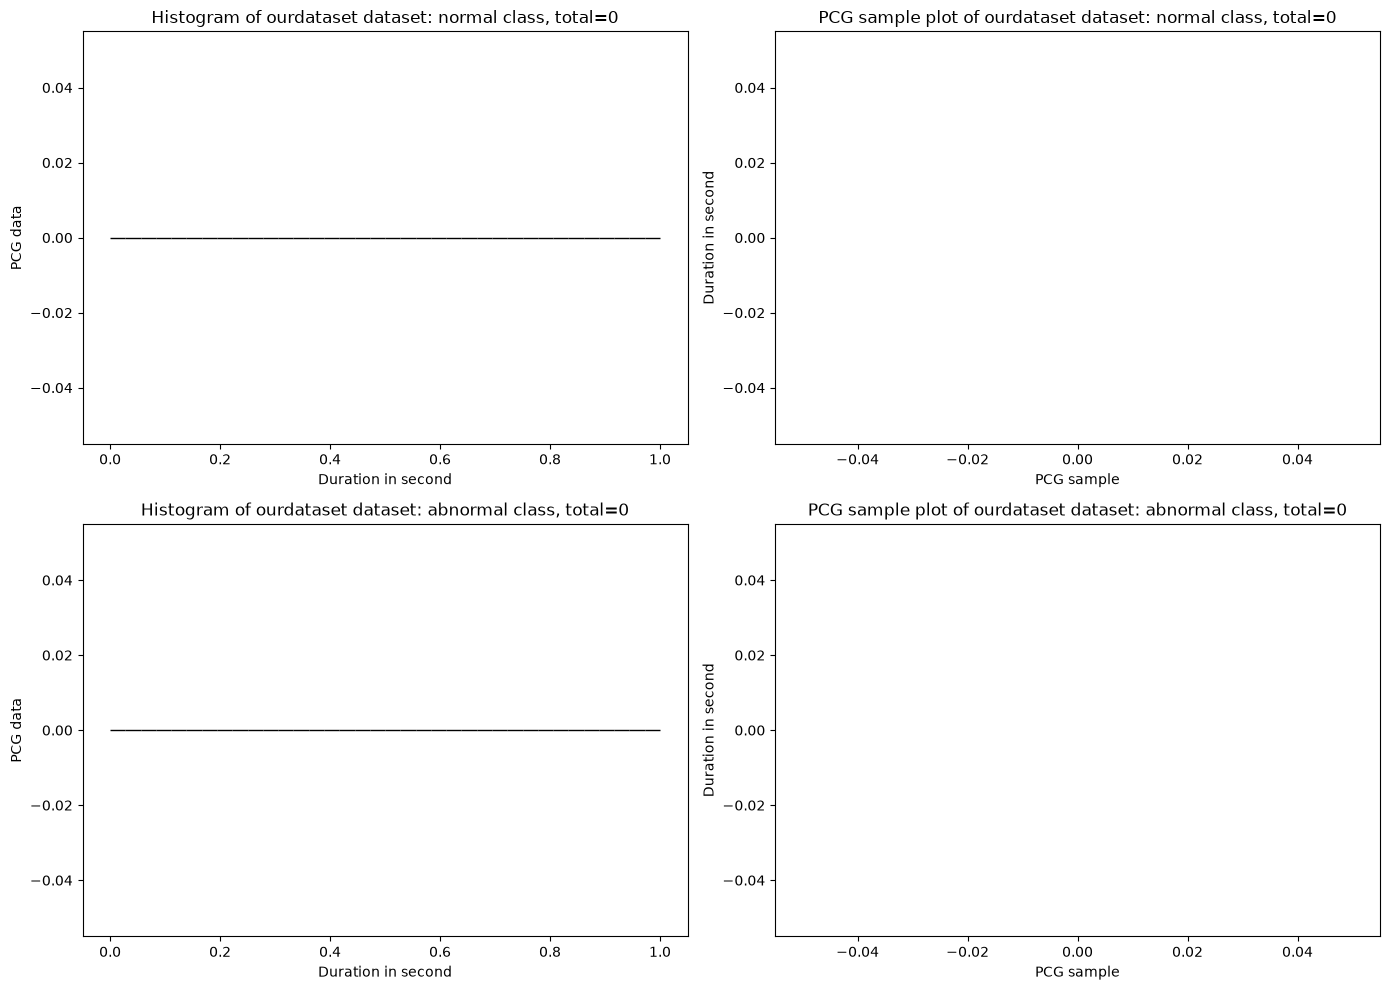

In [12]:
# read back the durations we saved
duration_normal = load_data(project_folder + "wavs_duration_normal_train.data")
duration_abnormal = load_data(project_folder + "wavs_duration_abnormal_train.data")

# ONE figure with 4 plots: 2 rows (normal, abnormal) x 2 columns (histogram, scatter)
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
getHIST(duration_normal, "normal", "Duration in second", "PCG data")

plt.subplot(2, 2, 2)
PlotScatter(duration_normal, "normal", "green", "PCG sample", "Duration in second")

plt.subplot(2, 2, 3)
getHIST(duration_abnormal, "abnormal", "Duration in second", "PCG data")

plt.subplot(2, 2, 4)
PlotScatter(duration_abnormal, "abnormal", "green", "PCG sample", "Duration in second")

plt.tight_layout()    # adds space so the titles don't overlap
plt.show()

In [13]:
# np.std = standard deviation (écart-type): how far the values are from their mean
a = np.array([[1, 2], [3, 4]])
print(np.std(a))            # all the values together
print(np.std(a, axis=0))    # column by column
print(np.std(a, axis=1))    # row by row

1.118033988749895
[1. 1.]
[0.5 0.5]


In [14]:
def signaltonoise(a, axis=0, ddof=0):
    a = np.asanyarray(a)
    m = a.mean(axis)                        # mean (moyenne)
    sd = a.std(axis=axis, ddof=ddof)        # standard deviation (écart-type)
    return np.where(sd == 0, 0, m / sd)     # if std = 0 -> SNR = 0 (we can't divide by 0)


# small example from the course
Arr = [[20, 4, 7, 1, 34], [50, 12, 15, 34, 5]]
singleChannel = np.sum(Arr, axis=1)     # sum of each row -> ONE channel: [66, 116]
print("# Single channel:", singleChannel)

# normalise: divide by the biggest absolute value -> values between -1 and 1
norm = singleChannel / max(np.amax(singleChannel), -1 * np.amin(singleChannel))
print("# Norm:", norm)

snr = signaltonoise(norm)
print("# Signal to Noise Ratio:", snr)

# Single channel: [ 66 116]
# Norm: [0.56896552 1.        ]
# Signal to Noise Ratio: 3.6400000000000006


In [15]:
X = np.array([[-1, -1], [-2, -1], [-3, -2], [1, 1], [2, 1], [3, 2]])

bandwidths = [0.1, 0.2, 0.3, 0.4, 0.5]
for bd in bandwidths:
    kde = KernelDensity(kernel="gaussian", bandwidth=bd).fit(X)
    scores = kde.score_samples(X)     # log of the density at each point
    print("# bandwidth :", bd)
    print(scores)

# bandwidth : 0.1
[0.97553365 0.97553365 0.97553365 0.97553365 0.97553365 0.97553365]
# bandwidth : 0.2
[-0.41075698 -0.41075698 -0.41076071 -0.41075698 -0.41075698 -0.41076071]
# bandwidth : 0.3
[-1.21783246 -1.21781757 -1.22167598 -1.21783246 -1.21781757 -1.22167598]
# bandwidth : 0.4
[-1.75405584 -1.75220849 -1.79512632 -1.75405584 -1.75220849 -1.79512632]
# bandwidth : 0.5
[-2.11637408 -2.10041055 -2.22514766 -2.11637408 -2.10041055 -2.22514766]


In [16]:
# Normal heartbeat SOUND
file_source = pascal_folder + "set_b/normal_noisynormal_101_1305030823364_B.wav"
signal, sample_rate = librosa.load(file_source)    # librosa changes the sample rate to 22050 Hz by default

plt.figure(figsize=(14, 5))
librosa.display.waveshow(signal, sr=sample_rate)
plt.title("Normal heartbeat - full signal")
plt.show()

ipd.display(ipd.Audio(file_source))    # listen to it

signal = signal[0:int(3.5 * sample_rate)]    # keep only the first 3.5 seconds
plt.figure(figsize=(14, 5))
librosa.display.waveshow(signal, sr=sample_rate)
plt.title("Normal heartbeat - first 3.5 seconds")
plt.show()

LibsndfileError: Error opening 'C:\\Users\\azizb\\Downloads\\CardioAgent-Ops\\Data\\dataset\\pascalset_b/normal_noisynormal_101_1305030823364_B.wav': System error.

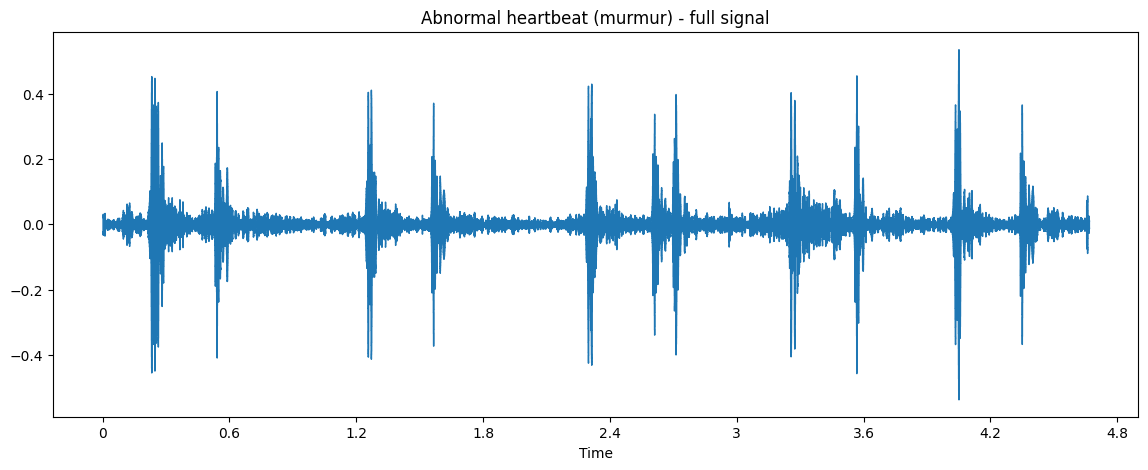

In [ ]:
# Abnormal heartbeat SOUND (murmur) -- other variable names, so we don't replace "signal"
murmur_file = pascal_folder + "set_b/murmur__112_1306243000964_A.wav"
murmur_signal, murmur_rate = librosa.load(murmur_file)

plt.figure(figsize=(14, 5))
librosa.display.waveshow(murmur_signal, sr=murmur_rate)
plt.title("Abnormal heartbeat (murmur) - full signal")
plt.show()

ipd.display(ipd.Audio(murmur_file))    # listen to it

In [17]:
n_fft = 2048
D = np.abs(librosa.stft(signal[:n_fft], n_fft=n_fft, hop_length=n_fft + 1))
plt.plot(D)
plt.title("FFT of one window (the first 2048 samples)")
plt.show()

NameError: name 'signal' is not defined

In [18]:
hop_length = 512
D = np.abs(librosa.stft(signal, n_fft=n_fft, hop_length=hop_length))
librosa.display.specshow(D, sr=sample_rate, x_axis="time", y_axis="linear")
plt.colorbar()
plt.show()

NameError: name 'signal' is not defined

In [19]:
DB = librosa.amplitude_to_db(D, ref=np.max)    # amplitude -> decibels
librosa.display.specshow(DB, sr=sample_rate, hop_length=hop_length, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.show()

NameError: name 'D' is not defined

In [20]:
n_mels = 128
mel = librosa.filters.mel(sr=sample_rate, n_fft=n_fft, n_mels=n_mels)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)    # (rows, columns, which plot)
librosa.display.specshow(mel, sr=sample_rate, hop_length=hop_length, x_axis="linear")
plt.ylabel("Mel filter")
plt.colorbar()
plt.title("1. Our filter bank for converting from Hz to mels.")

plt.subplot(1, 3, 2)
mel_10 = librosa.filters.mel(sr=sample_rate, n_fft=n_fft, n_mels=10)
librosa.display.specshow(mel_10, sr=sample_rate, hop_length=hop_length, x_axis="linear")
plt.ylabel("Mel filter")
plt.colorbar()
plt.title("2. Easier to see what is happening with only 10 mels.")

plt.subplot(1, 3, 3)
for i in [0, 9, 49, 99, 127]:
    plt.plot(mel[i])
plt.legend(["1", "10", "50", "100", "128"])
plt.title("3. Plotting some triangular filters separately.")

plt.tight_layout()
plt.show()

NameError: name 'sample_rate' is not defined

In [21]:
# one window of the spectrogram, before (Hz) and after converting to mel
plt.plot(D[:, 1])
plt.plot(mel.dot(D[:, 1]))
plt.legend(["Hz", "mel"])
plt.title("One sampled window for example, before and after converting to mel.")
plt.show()

NameError: name 'D' is not defined

In [22]:
S = librosa.feature.melspectrogram(y=signal, sr=sample_rate, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels)
S_DB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_DB, sr=sample_rate, hop_length=hop_length, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.show()

NameError: name 'signal' is not defined

In [23]:
def get_wav_snr(folder):
    wavs_snr = []
    for file in glob(folder + "*.wav"):
        data, rate = librosa.load(file, sr=None)
        # librosa already gives ONE channel, so no need for np.sum(axis=1) like in the course
        norm = data / max(np.amax(data), -1 * np.amin(data))    # normalise, like in the course
        snr = signaltonoise(norm)                                 # SNR function of the course
        wavs_snr.append(float(snr))
    return wavs_snr


def getSNR(class_name):
    wavs_snr = get_wav_snr(ourdataset_folder + class_name + "/")

    file_name = project_folder + "snr_" + class_name + "_train.data"
    with open(file_name, "wb") as f:
        pickle.dump(wavs_snr, f)

    print(class_name, ":", len(wavs_snr), "SNR saved in", file_name)


getSNR("abnormal")    # -> snr_abnormal_train.data
getSNR("normal")      # -> snr_normal_train.data

abnormal : 0 SNR saved in C:\Users\azizb\Downloads\CardioAgent-Opssnr_abnormal_train.data
normal : 0 SNR saved in C:\Users\azizb\Downloads\CardioAgent-Opssnr_normal_train.data


In [24]:
def PlotKDE(data, class_name, x_txt):
    sns.kdeplot(data, color="darkblue", linewidth=2, label="KDE")    # the KDE curve
    sns.rugplot(data, color="black")                                  # one small tick per wav
    plt.title("Density plot of ourdataset dataset: " + class_name + " class, total=" + str(len(data)))
    plt.xlabel(x_txt)
    plt.ylabel("Density")
    plt.legend()


def PlotHistKDE(data, class_name, x_txt):
    sns.histplot(data, bins=36, stat="density", color="darkblue", alpha=0.4)    # histogram (as density)
    sns.kdeplot(data, color="red", linewidth=2, label="KDE")                     # KDE curve on top
    sns.rugplot(data, color="green")
    plt.title("Histogram of ourdataset dataset: " + class_name + " class, total=" + str(len(data)))
    plt.xlabel(x_txt)
    plt.ylabel("Density")
    plt.legend()

In [25]:
wavs = glob(ourdataset_folder + "normal/*.wav")
file_source = wavs[20]                        # PCG sample index 20
print("file:", os.path.basename(file_source))

signal, sample_rate = librosa.load(file_source)    # 22050 Hz by default, like in the course
n_fft = 2048
hop_length = 512

# FFT -> spectrogram in dB
D = np.abs(librosa.stft(signal, n_fft=n_fft, hop_length=hop_length))
DB = librosa.amplitude_to_db(D, ref=np.max)

# Mel spectrogram in dB
S = librosa.feature.melspectrogram(y=signal, sr=sample_rate, n_fft=n_fft, hop_length=hop_length, n_mels=128)
S_DB = librosa.power_to_db(S, ref=np.max)

IndexError: list index out of range

NameError: name 'DB' is not defined

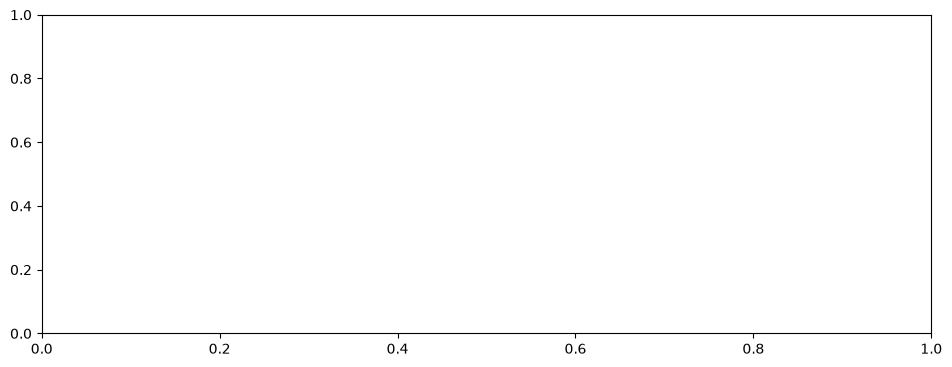

In [26]:
# read back the 4 lists we saved
snr_normal = load_data(project_folder + "snr_normal_train.data")
snr_abnormal = load_data(project_folder + "snr_abnormal_train.data")
duration_normal = load_data(project_folder + "wavs_duration_normal_train.data")
duration_abnormal = load_data(project_folder + "wavs_duration_abnormal_train.data")

# ONE figure: 5 rows x 4 columns -> places 1 to 20
plt.figure(figsize=(24, 24))

# row 1: FFT and Mel Spectrogram of PCG sample 20 -- (1, 2) = takes places 1 AND 2
plt.subplot(5, 4, (1, 2))
librosa.display.specshow(DB, sr=sample_rate, hop_length=hop_length, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("PCG sample index:20 FFT plot")

plt.subplot(5, 4, (3, 4))
librosa.display.specshow(S_DB, sr=sample_rate, hop_length=hop_length, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("PCG sample index:20 Mel Spectrogram plot")

# row 2: SNR - normal
plt.subplot(5, 4, 5)
getHIST(snr_normal, "normal", "Signal to Noise Ratio", "PCG data")
plt.subplot(5, 4, 6)
PlotKDE(snr_normal, "normal", "Signal to Noise Ratio")
plt.subplot(5, 4, 7)
PlotHistKDE(snr_normal, "normal", "Signal to Noise Ratio")
plt.subplot(5, 4, 8)
PlotScatter(snr_normal, "normal", "red", "PCG sample", "Signal to Noise Ratio")

# row 3: SNR - abnormal
plt.subplot(5, 4, 9)
getHIST(snr_abnormal, "abnormal", "Signal to Noise Ratio", "PCG data")
plt.subplot(5, 4, 10)
PlotKDE(snr_abnormal, "abnormal", "Signal to Noise Ratio")
plt.subplot(5, 4, 11)
PlotHistKDE(snr_abnormal, "abnormal", "Signal to Noise Ratio")
plt.subplot(5, 4, 12)
PlotScatter(snr_abnormal, "abnormal", "red", "PCG sample", "Signal to Noise Ratio")


plt.tight_layout()
plt.show()